In [278]:
import torchxrayvision as xrv
import torch, torchvision
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt

# Projection algorithms
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, Isomap
import umap.umap_ as umap
import pacmap

### Constants and Configs

In [279]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Fixed seed for reproducibility
RANDOM_STATE = 42

In [280]:
pathologies = [
    "Lung Opacity",
    "Fracture",
    # TODO: check if we should add this or not
    #"Nodule/Mass",
    "Pneumothorax"
]

### Load and Prepare Dataset

In [281]:
def load_dataset(image_path: str = "./nih_data_small", datasetClass = xrv.datasets.NIH_Google_Dataset):
    transform = torchvision.transforms.Compose([xrv.datasets.XRayCenterCrop(),xrv.datasets.XRayResizer(224)])
    d_nih = datasetClass(imgpath=image_path, transform=transform)
    print(f'found {len(d_nih)} images')
    return d_nih

In [282]:
dataset = load_dataset()
dataset_pathologies = list(dataset.pathologies)
dataset_label_indices = {
    name: dataset_pathologies.index(name)
    for name in pathologies
}
dataset_indices_label = {dataset_label_indices[l]:l for l in dataset_label_indices}

found 810 images


In [283]:
dataset_indices_label

{0: 'Lung Opacity', 1: 'Fracture', 3: 'Pneumothorax'}

In [284]:
image_features_list = []
labels_list = []
for i in range(len(dataset)):
    sample = dataset[i]
    label = np.asarray(sample["lab"]).reshape(-1)
    label_int = int(np.argmax(label))
    if label_int in dataset_indices_label:
        img = np.asarray(sample["img"]).squeeze()
        image_features_list.append(
                    img.astype(np.float32).reshape(-1)
        )
        
        labels_list.append(
                label
            )

image_features = np.stack(
    image_features_list,
    axis=0
)
labels_list_int = np.argmax(labels_list, axis=1)


### Load model

In [285]:
def load_model(model_weights: str = "densenet121-res224-chex"):
    model = xrv.models.DenseNet(weights=model_weights)
    model.eval()
    return model.to(DEVICE)

In [286]:
model = load_model()
model.eval()

XRV-DenseNet121-densenet121-res224-chex

In [287]:
model_to_dataset_indices = {
    model_idx: dataset_label_indices[pathology]
    for model_idx, pathology in enumerate(model.pathologies)
    if pathology in dataset_label_indices
}

print(model_to_dataset_indices)

{3: 3, 15: 1, 16: 0}


In [302]:
def calculate_model_predictions_score(feature_space, model, dataset_label_indices):
    model.eval()

    # Convert flattened images to (N, 1, 224, 224)
    images = torch.as_tensor(feature_space, dtype=torch.float32)
    images = images.reshape(-1, 1, 224, 224).to(DEVICE)

    with torch.no_grad():
        model_outputs = model(images)

    # Convert model outputs to NumPy
    model_outputs = model_outputs.cpu().numpy()

    # Find model output indices for labels in the dataset
    model_to_dataset_indices = {
        pathology: idx
        for idx, pathology in enumerate(model.pathologies)
        if pathology in dataset_label_indices
    }

    # Extract the relevant output columns in dataset label order
    dataset_labels = sorted(
        dataset_label_indices,
        key=dataset_label_indices.get
    )

    selected_indices = [
        next(
            idx for idx, pathology in enumerate(model.pathologies)
            if pathology == label
        )
        for label in dataset_labels
    ]

    selected_outputs = model_outputs[:, selected_indices]

    return selected_outputs

In [306]:
model_predictions = calculate_model_predictions_score(image_features, model, dataset_label_indices)

In [305]:
torch.nn.functional.softmax(torch.from_numpy(calculate_model_predictions_score(image_features, model, dataset_label_indices)))

tensor([[0.4243, 0.3558, 0.2199],
        [0.4102, 0.3860, 0.2038],
        [0.3942, 0.3574, 0.2484],
        ...,
        [0.3932, 0.3091, 0.2977],
        [0.4018, 0.3096, 0.2886],
        [0.3986, 0.3063, 0.2951]])

### Downprojection

In [ ]:
class Downprojector:

    def __init__(self, image_features):
        self.projection_cache = {}
        self.image_features = image_features


    def get_feature_matrix(self, feature_space):
        return self.image_features

    """
    PCA is used as a preprocessing step for the non-linear
        projection techniques.
    """
    def prepare_pca_features(self, feature_space):
        cache_key = f"{feature_space}_pca"
         
        if cache_key in self.projection_cache:
            return self.projection_cache[cache_key]
         
        X = self.get_feature_matrix(feature_space)
         
             # Keep at most 50 dimensions before expensive
             # non-linear dimensionality reduction.
        n_components = min(
                 50,
                 X.shape[0],
                 X.shape[1]
             )
         
        pca = PCA(
                 n_components=n_components,
                 random_state=RANDOM_STATE
        )
         
        X_pca = pca.fit_transform(X)
         
        self.projection_cache[cache_key] = {
                 "data": X_pca,
                 "pca": pca
             }
         
        return self.projection_cache[cache_key]

    def calculate_projection(self, feature_space: str, method: str):
        cache_key = (
                f"{feature_space}_{method}"
            )
        
        if cache_key in self.projection_cache:
            return self.projection_cache[cache_key]


        if method == "PCA":

            X = self.get_feature_matrix(feature_space)

            reducer = PCA(
                n_components=2,
                random_state=RANDOM_STATE
            )

            embedding = reducer.fit_transform(X)
        elif method == "t-SNE":
        
            X_pca = self.prepare_pca_features(
                    feature_space
                )["data"]
        
                # t-SNE requires perplexity < number of samples.
            perplexity = min(
                    30,
                    max(5, (X_pca.shape[0] - 1) // 3)
                )
        
            reducer = TSNE(
                    n_components=2,
                    perplexity=perplexity,
                    init="pca",
                    learning_rate="auto",
                    random_state=RANDOM_STATE
                )
        
            embedding = reducer.fit_transform(
                    X_pca
                )
        self.projection_cache[cache_key] = embedding
        return embedding

### Run first visualization

In [ ]:
def visualize_space(feature_space, projection_method):
    for index, name in dataset_indices_label.items():
        idx = labels_list_int == index
        plt.scatter(feature_space[idx,0], feature_space[idx,1], label=name)
    plt.title(f"{projection_method} Projection Colored")
    plt.xlabel(f"{projection_method} 1")
    plt.ylabel(f"{projection_method} 2")
    plt.legend()
    plt.show()

In [ ]:
downprojector = Downprojector(image_features)

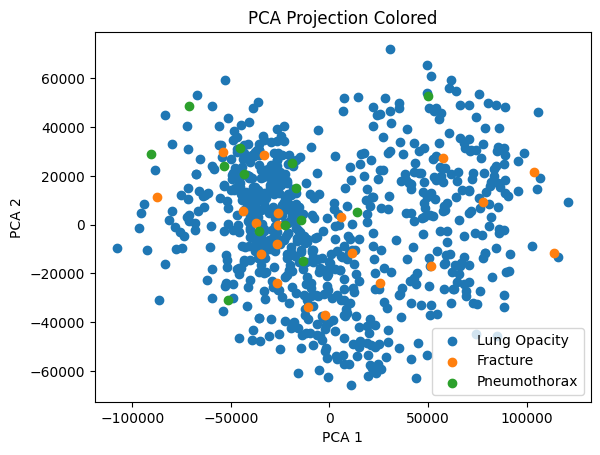

In [ ]:
X_pca = downprojector.calculate_projection('NIH_Google_Dataset', 'PCA')
visualize_space(X_pca, 'PCA')


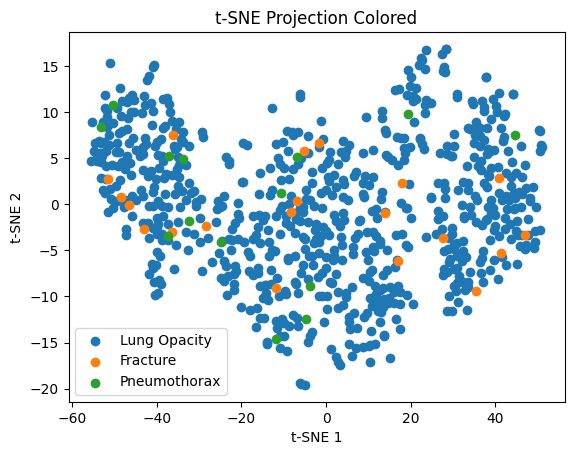

In [ ]:
tsne = downprojector.calculate_projection('NIH_Google_Dataset', 't-SNE')
visualize_space(tsne, 't-SNE')

### Visualize predictions


In [307]:
def visualize_space(feature_space, projection_method, predictions,
                    label_name="Pneumothorax"):

    # Find the prediction column for this finding
    label_names = ["Lung Opacity", "Fracture", "Pneumothorax"]
    label_index = label_names.index(label_name)

    # Get the model score for each image
    scores = predictions[:, label_index]

    plt.figure(figsize=(10, 7))

    scatter = plt.scatter(
        feature_space[:, 0],
        feature_space[:, 1],
        c=scores,
        cmap="viridis",
        alpha=0.8,
        s=20
    )

    plt.colorbar(scatter, label=f"Model score: {label_name}")
    plt.title(f"{projection_method} Projection Colored by {label_name} Score")
    plt.xlabel(f"{projection_method} 1")
    plt.ylabel(f"{projection_method} 2")
    plt.show()

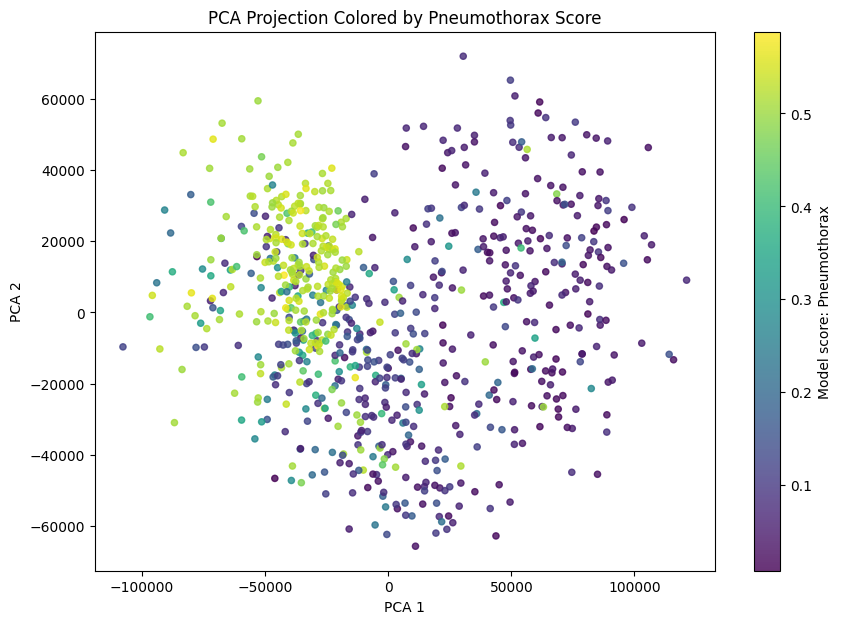

In [312]:
visualize_space(X_pca, 'PCA', model_predictions)

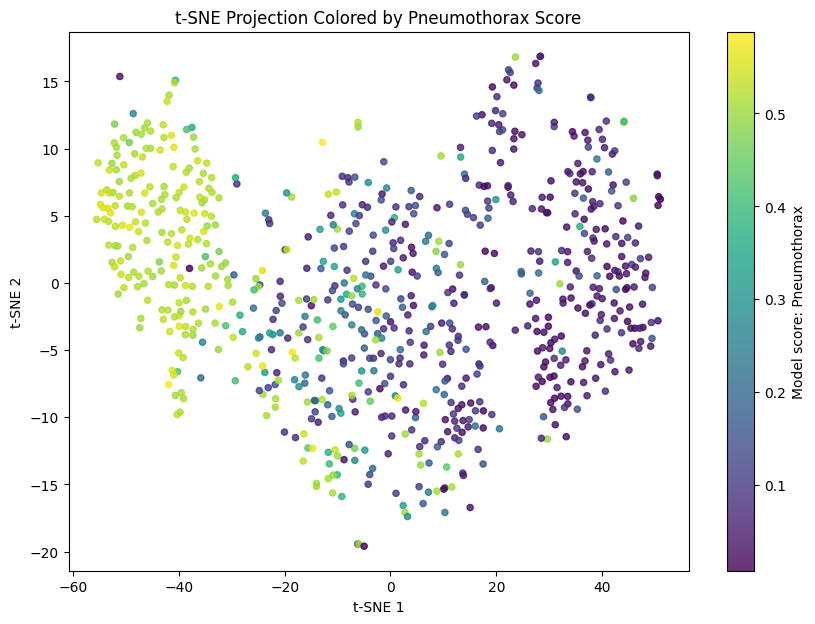

In [308]:
visualize_space(tsne, 't-SNE', model_predictions)

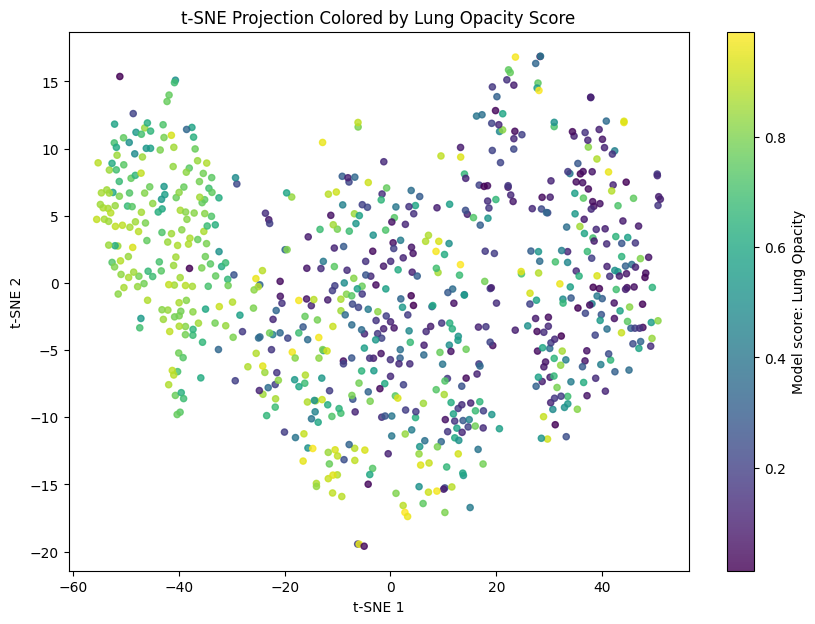

In [309]:
visualize_space(tsne, 't-SNE', model_predictions, "Lung Opacity")

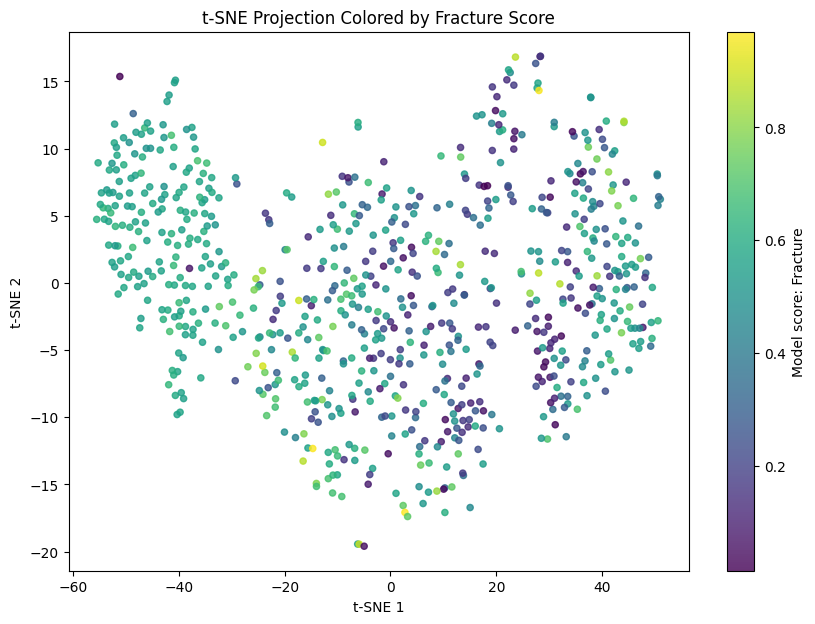

In [310]:
visualize_space(tsne, 't-SNE', model_predictions, "Fracture")